# Overfitting trials: which single change reduces memorizing?

**Problem.** Our `full` PatchVision-X run reaches ~98% accuracy on clean *training* photos but only ~48% on *validation* photos
(a memorizing gap of ~50 points). The validation loss is lowest around epoch 140 and then rises.

**Experiment.** Four trial runs. Each one is the `full` recipe (same data, same splits, same seed 42, same 300-epoch schedule,
same early stopping with patience 60) with **exactly one regularisation setting changed**:

| Trial (= results folder) | The one change |
|---|---|
| `ovf1_droppath0.3` | stochastic depth 0.1 -> 0.3 |
| `ovf2_wd0.1` | weight decay 0.05 -> 0.1 |
| `ovf3_autoaug` | augmentation tier `strong` -> `auto` (TrivialAugmentWide) |
| `ovf4_dropout0.1` | dropout 0 -> 0.1 (MLP / projections and attention weights) |

Reference rows `full` and `base` come from the earlier runs (seed 42).

### Decision rule (written BEFORE seeing any trial result)
We judge on **validation** numbers only. The test photos are evaluated automatically at the end of every run and are listed
"for the record", but they are **not** used to choose anything.

A trial counts as an **improvement over `full`** if both hold:
1. its **minimum validation loss** is lower than `full`'s by at least **0.03** (validation loss is the most sensitive overfitting signal), and
2. its **smoothed validation accuracy** (best 10-epoch rolling mean) is **not more than 1 point below** `full`'s.

The memorizing gap (clean-train minus validation accuracy near the best epoch) is reported as a diagnostic: a smaller gap
only counts as good if validation accuracy did not drop with it (a model that underfits also has a small gap).
The validation set has only 600 photos (3 per species), so a change of 1-2 points in validation accuracy is within noise.

**Everything is recorded:** every run writes `train_log.txt` (each step and each epoch), `steps.csv`, `history.csv`,
`config.json`, `env.json`, curves, attention snapshots and checkpoints to `results/<trial>/seed42/`.
The comparison table and plots are written to `results/overfitting_trials/`.

In [1]:
import sys, json, dataclasses
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))          # the folder that contains patchvision/

import torch, pandas as pd
from IPython.display import Image as show_image, display

from patchvision.config import PathsConfig, get_experiment, get_trial, overfit_trials
from patchvision.data import load_data_info, build_loaders
from patchvision.experiment import run_experiment, compare_runs
from patchvision import visualize as viz

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU ONLY - far too slow")

torch 2.5.1+cu124 | CUDA: True | NVIDIA GeForce RTX 4090


## 1. Settings

In [2]:
SEED             = 42
NUM_WORKERS      = 6        # data-loading processes
STEP_PRINT_EVERY = 21       # print every 21st step (the log FILE of each run always has every step)
RESUME           = True     # a finished trial is not re-run; an interrupted one continues from last.pt
PATHS            = PathsConfig(root=".")
TRIALS           = list(overfit_trials())
print("trials:", TRIALS)
print("results go to:", PATHS.results)

trials: ['ovf1_droppath0.3', 'ovf2_wd0.1', 'ovf3_autoaug', 'ovf4_dropout0.1']
results go to: C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results


### What exactly differs from `full` in each trial (computed from the configs, not typed by hand)

In [3]:
ref = dataclasses.asdict(get_experiment("full", SEED))
rows = []
for n in TRIALS:
    e = dataclasses.asdict(get_trial(n, SEED))
    for sect in ("model", "train"):
        for k, v in e[sect].items():
            if ref[sect][k] != v:
                rows.append({"trial": n, "setting": f"{sect}.{k}", "full": ref[sect][k], "this trial": v})
    # everything else must be identical to full
    same = all(ref[s][k] == e[s][k] for s in ("model", "train") for k in e[s] if (n, f"{s}.{k}") not in {(r["trial"], r["setting"]) for r in rows})
    assert same, f"{n} differs from full in more than the listed settings"
display(pd.DataFrame(rows))

,trial,setting,full,this trial
0,ovf1_droppath0.3,model.drop_path,0.1,0.3
1,ovf2_wd0.1,train.weight_decay,0.05,0.1
2,ovf3_autoaug,train.aug_tier,strong,auto
3,ovf4_dropout0.1,model.drop,0.0,0.1
4,ovf4_dropout0.1,model.attn_drop,0.0,0.1


## 2. Reference runs (already finished earlier, seed 42)

In [4]:
ref_table = compare_runs(PATHS, ["base", "full"], seed=SEED, out_name="_reference")
display(ref_table.round(2))

,run,finished,epochs_run,best_val_acc1,best_val_epoch,smoothed_val_acc1,min_val_loss,min_val_loss_epoch,clean_train_acc_at_best,gap_at_best,val_attn_in_box,train_min,sec_per_epoch,test_acc1 (record only),test_ece (record only)
0,base,True,246,42.33,186,40.80,2.72,114,99.50,59.83,0.35,48.42,11.81,39.52,2.49
1,full,True,213,48.50,153,48.38,2.32,140,98.17,49.83,0.66,71.20,20.06,47.39,5.95


## 3.1 Trial 1: `ovf1_droppath0.3`

TRIAL ovf1_droppath0.3 | stochastic depth 0.1 -> 0.3 (randomly skip whole blocks while training)


RUN ovf1_droppath0.3 | seed 42 | device cuda | AMP True (torch.bfloat16)


model  4.27 M params | ModelConfig(img_size=224, num_classes=200, embed_dim=256, depth=8, heads=8, mlp_ratio=3.0, drop=0.0, attn_drop=0.0, drop_path=0.3, tok_groups=4, pool_after=None, pool_ratio=4, adj_mode='hadamard', use_sparse_gate=True, use_lfe=True, keep_abs_pos=False, use_multiscale=True, scales=(1, 2, 4, 0))


train  TrainConfig(epochs=300, batch_size=64, lr=0.0005, min_lr=1e-06, warmup_epochs=10, weight_decay=0.05, betas=(0.9, 0.999), grad_clip=1.0, label_smoothing=0.1, amp=True, aug_tier='strong', use_mixup_cutmix=True, use_bbox_loss=True, bbox_weight=0.1, use_ema=True, ema_decay=0.999, use_consistency=True, cons_logit_weight=1.0, cons_attn_weight=1.0, use_box_crop=True, box_crop_prob=0.3, box_crop_margin=(0.1, 0.4), best_metric='acc1', early_stop_patience=60, early_stop_start=30, clean_eval_every=5, clean_eval_size=600, snapshot_every=10, weights_every=50, plot_every=10)


data   splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | steps/epoch 84 | total steps 25,200


...

worst 10 classes (F1):
 class_id                class_name  precision    recall        f1  support
      141                Black Tern  15.789474 10.000000 12.244898       30
       90               Mockingbird  27.272727 10.000000 14.634146       30
       29                 Fish Crow  14.285714 16.666667 15.384615       30
      106              Common Raven  14.705882 16.666667 15.625000       30
       42 Yellow bellied Flycatcher  20.000000 13.793103 16.326531       29
       28             American Crow  25.000000 13.333333 17.391304       30
       61              Herring Gull  18.518519 16.666667 17.543860       30
       22          Brandt Cormorant  18.518519 17.241379 17.857143       29
       64         Slaty backed Gull  27.272727 15.000000 19.354839       20
       70        Long tailed Jaeger  27.777778 16.666667 20.833333       30


best 10 classes (F1):
 class_id                class_name  precision    recall        f1  support
       54          Evening Grosbeak 100.000000 80.000000 88.888889       30
       74                 Green Jay  88.461538 85.185185 86.792453       27
       69           Green Violetear  77.777778 93.333333 84.848485       30
       15           Painted Bunting  82.758621 85.714286 84.210526       28
       82 White breasted Kingfisher  92.000000 76.666667 83.636364       30
       11   Yellow headed Blackbird  74.193548 88.461538 80.701754       26
      163          Cerulean Warbler  80.000000 80.000000 80.000000       30
       84               Horned Lark  75.757576 83.333333 79.365079       30
      187       Pileated Woodpecker  91.304348 70.000000 79.245283       30
       56    Rose breasted Grosbeak  84.615385 73.333333 78.571429       30


most frequent confusions (true -> predicted : count):
  Herring Gull -> California Gull : 9
  Artic Tern -> Common Tern : 9
  Elegant Tern -> Caspian Tern : 9
  Nelson Sharp tailed Sparrow -> Le Conte Sparrow : 7
  Western Gull -> California Gull : 7
  Great Grey Shrike -> Loggerhead Shrike : 7
  Common Tern -> Artic Tern : 7
  Anna Hummingbird -> Ruby throated Hummingbird : 7
  Horned Grebe -> Eared Grebe : 7
  American Crow -> Fish Crow : 6
  American Crow -> Common Raven : 6
  Black billed Cuckoo -> Yellow billed Cuckoo : 6
  Yellow bellied Flycatcher -> Acadian Flycatcher : 6
  Western Wood Pewee -> Olive sided Flycatcher : 6
  Acadian Flycatcher -> Least Flycatcher : 6



Saved everything to C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\ovf1_droppath0.3\seed42


experiment                                                      ovf1_droppath0.3
seed                                                                          42
best_epoch                                                                   246
epochs_run                                                                   300
stopped_early                                                              False
train_time_s                                                            5809.897
sec_per_epoch                                                             19.366
best_val_acc1                                                             51.667
val_acc1_at_best                                                          51.667
overfit_gap_clean_minus_val                                               48.333
test_acc1                                                                 52.071
test_acc5                                                                 75.147
test_macro_f1               

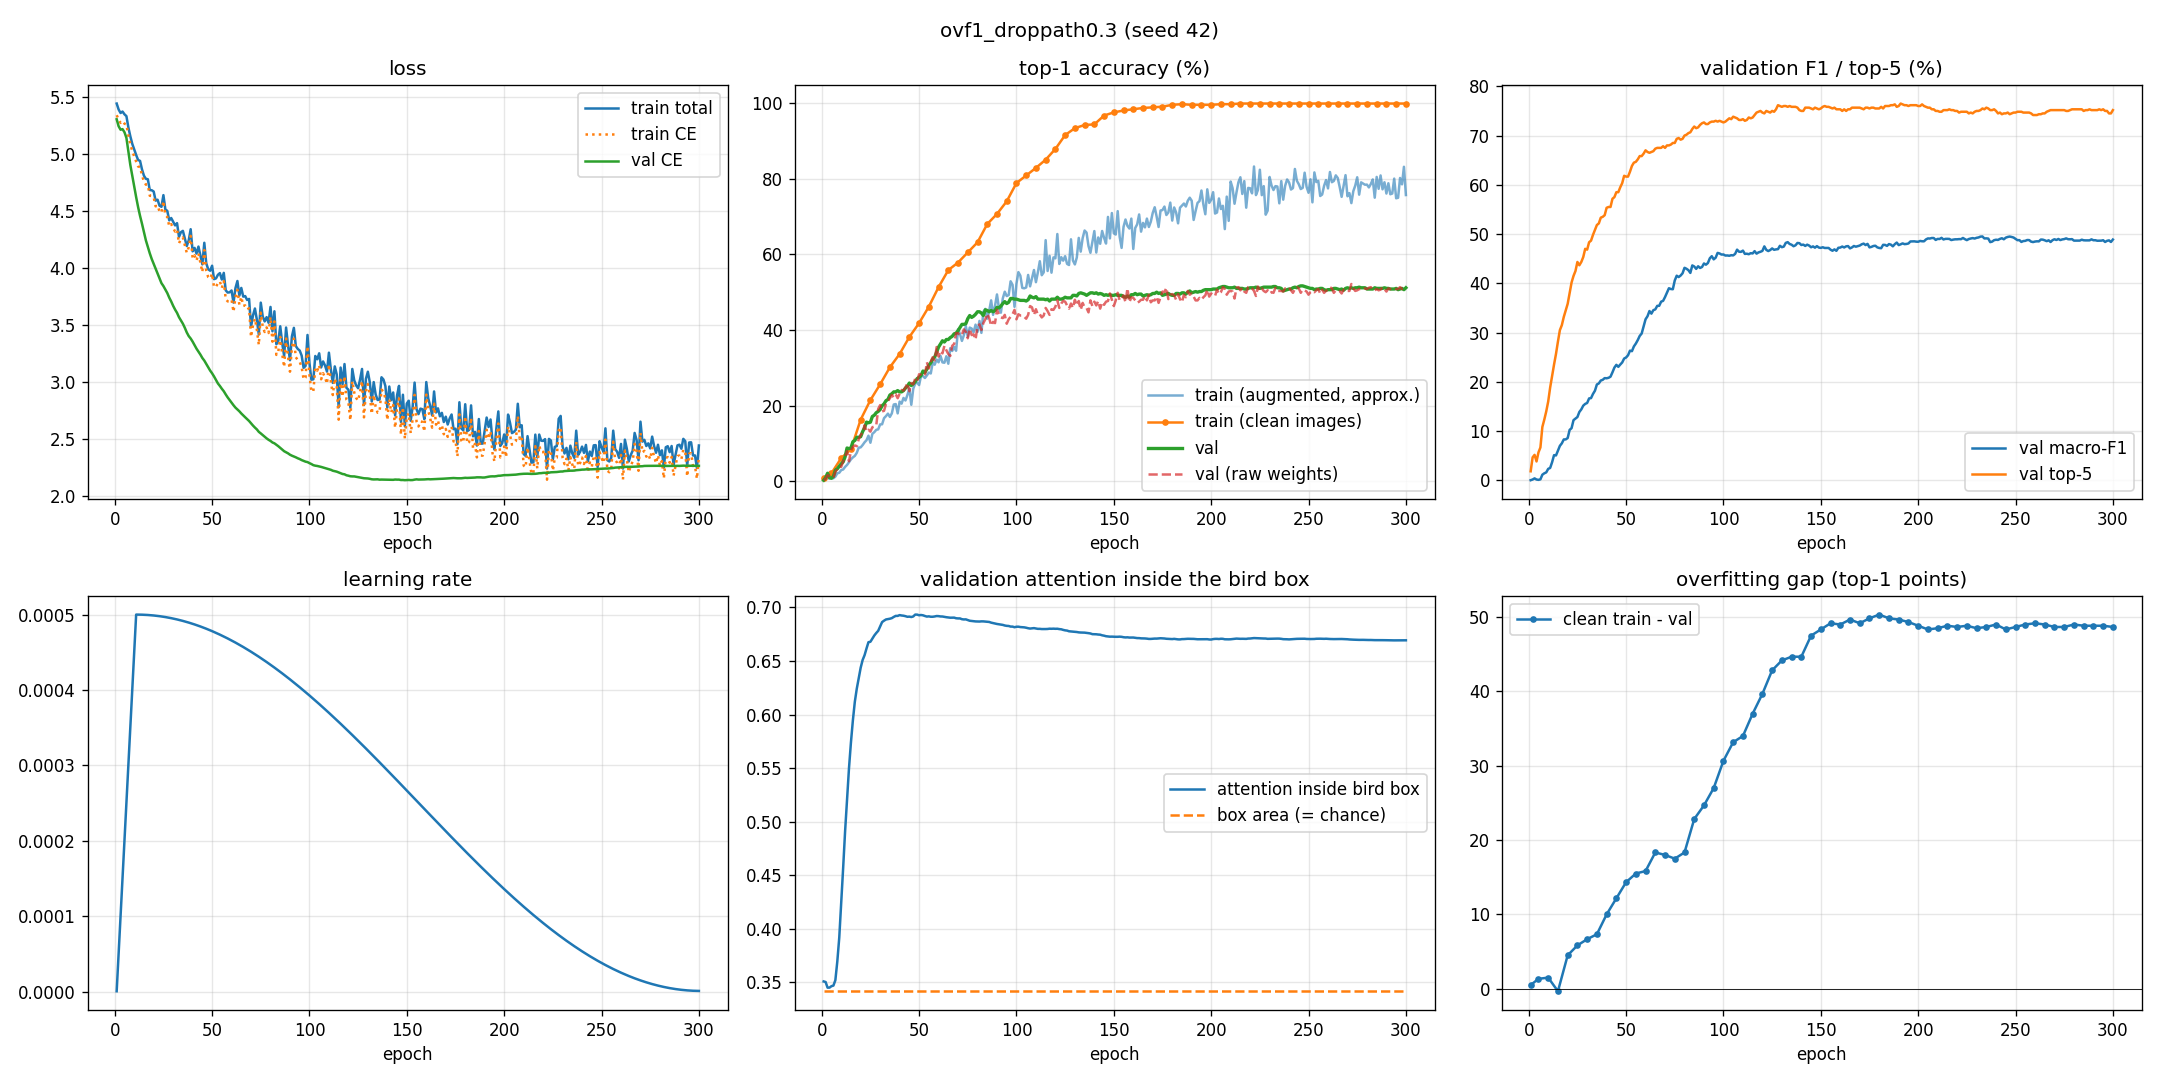

In [5]:
NAME = "ovf1_droppath0.3"
exp = get_trial(NAME, SEED)
print("TRIAL", NAME, "|", overfit_trials()[NAME]["change"])
row = run_experiment(exp, PATHS, num_workers=NUM_WORKERS, step_print_every=STEP_PRINT_EVERY, resume=RESUME)
display(pd.Series({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()}))
run_dir = PATHS.results / NAME / f"seed{SEED}"
display(show_image(filename=str(run_dir / "curves.png")))

## 3.2 Trial 2: `ovf2_wd0.1`

TRIAL ovf2_wd0.1 | weight decay 0.05 -> 0.1 (pull all weights harder towards zero)


RUN ovf2_wd0.1 | seed 42 | device cuda | AMP True (torch.bfloat16)


model  4.27 M params | ModelConfig(img_size=224, num_classes=200, embed_dim=256, depth=8, heads=8, mlp_ratio=3.0, drop=0.0, attn_drop=0.0, drop_path=0.1, tok_groups=4, pool_after=None, pool_ratio=4, adj_mode='hadamard', use_sparse_gate=True, use_lfe=True, keep_abs_pos=False, use_multiscale=True, scales=(1, 2, 4, 0))


train  TrainConfig(epochs=300, batch_size=64, lr=0.0005, min_lr=1e-06, warmup_epochs=10, weight_decay=0.1, betas=(0.9, 0.999), grad_clip=1.0, label_smoothing=0.1, amp=True, aug_tier='strong', use_mixup_cutmix=True, use_bbox_loss=True, bbox_weight=0.1, use_ema=True, ema_decay=0.999, use_consistency=True, cons_logit_weight=1.0, cons_attn_weight=1.0, use_box_crop=True, box_crop_prob=0.3, box_crop_margin=(0.1, 0.4), best_metric='acc1', early_stop_patience=60, early_stop_start=30, clean_eval_every=5, clean_eval_size=600, snapshot_every=10, weights_every=50, plot_every=10)


data   splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | steps/epoch 84 | total steps 25,200


...

worst 10 classes (F1):
 class_id           class_name  precision    recall        f1  support
       64    Slaty backed Gull  11.111111  5.000000  6.896552       20
       28        American Crow  12.500000  6.666667  8.695652       30
      101   Western Wood Pewee  16.666667 10.000000 12.500000       30
       90          Mockingbird  17.647059 10.000000 12.765957       30
       29            Fish Crow  12.500000 16.666667 14.285714       30
       61         Herring Gull  19.047619 13.333333 15.686275       30
       22     Brandt Cormorant  20.000000 13.793103 16.326531       29
      107   White necked Raven  17.857143 16.666667 17.241379       30
      116 Clay colored Sparrow  17.241379 17.241379 17.241379       29
      196           Marsh Wren  18.518519 16.666667 17.543860       30


best 10 classes (F1):
 class_id             class_name  precision    recall        f1  support
       74              Green Jay  95.833333 85.185185 90.196078       27
       54       Evening Grosbeak 100.000000 76.666667 86.792453       30
       15        Painted Bunting  91.666667 78.571429 84.615385       28
       69        Green Violetear  79.411765 90.000000 84.375000       30
      190  Red headed Woodpecker  83.333333 83.333333 83.333333       30
      199    Common Yellowthroat  88.461538 76.666667 82.142857       30
      187    Pileated Woodpecker  88.461538 76.666667 82.142857       30
      188 Red bellied Woodpecker  76.470588 86.666667 81.250000       30
      163       Cerulean Warbler  85.185185 76.666667 80.701754       30
       34           Purple Finch  78.125000 83.333333 80.645161       30


most frequent confusions (true -> predicted : count):
  American Crow -> Fish Crow : 10
  Western Wood Pewee -> Olive sided Flycatcher : 8
  Herring Gull -> California Gull : 8
  Great Grey Shrike -> Loggerhead Shrike : 7
  Henslow Sparrow -> Baird Sparrow : 7
  Horned Grebe -> Eared Grebe : 7
  Elegant Tern -> Caspian Tern : 7
  Artic Tern -> Common Tern : 7
  Common Raven -> Fish Crow : 7
  White necked Raven -> Common Raven : 6
  White necked Raven -> American Crow : 6
  Parakeet Auklet -> Crested Auklet : 6
  Cardinal -> Vermilion Flycatcher : 6
  Acadian Flycatcher -> Least Flycatcher : 6
  Shiny Cowbird -> Boat tailed Grackle : 6



Saved everything to C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\ovf2_wd0.1\seed42


experiment                                                            ovf2_wd0.1
seed                                                                          42
best_epoch                                                                   148
epochs_run                                                                   208
stopped_early                                                               True
train_time_s                                                            4145.695
sec_per_epoch                                                             19.931
best_val_acc1                                                             50.833
val_acc1_at_best                                                          50.833
overfit_gap_clean_minus_val                                               49.167
test_acc1                                                                 50.035
test_acc5                                                                 75.147
test_macro_f1               

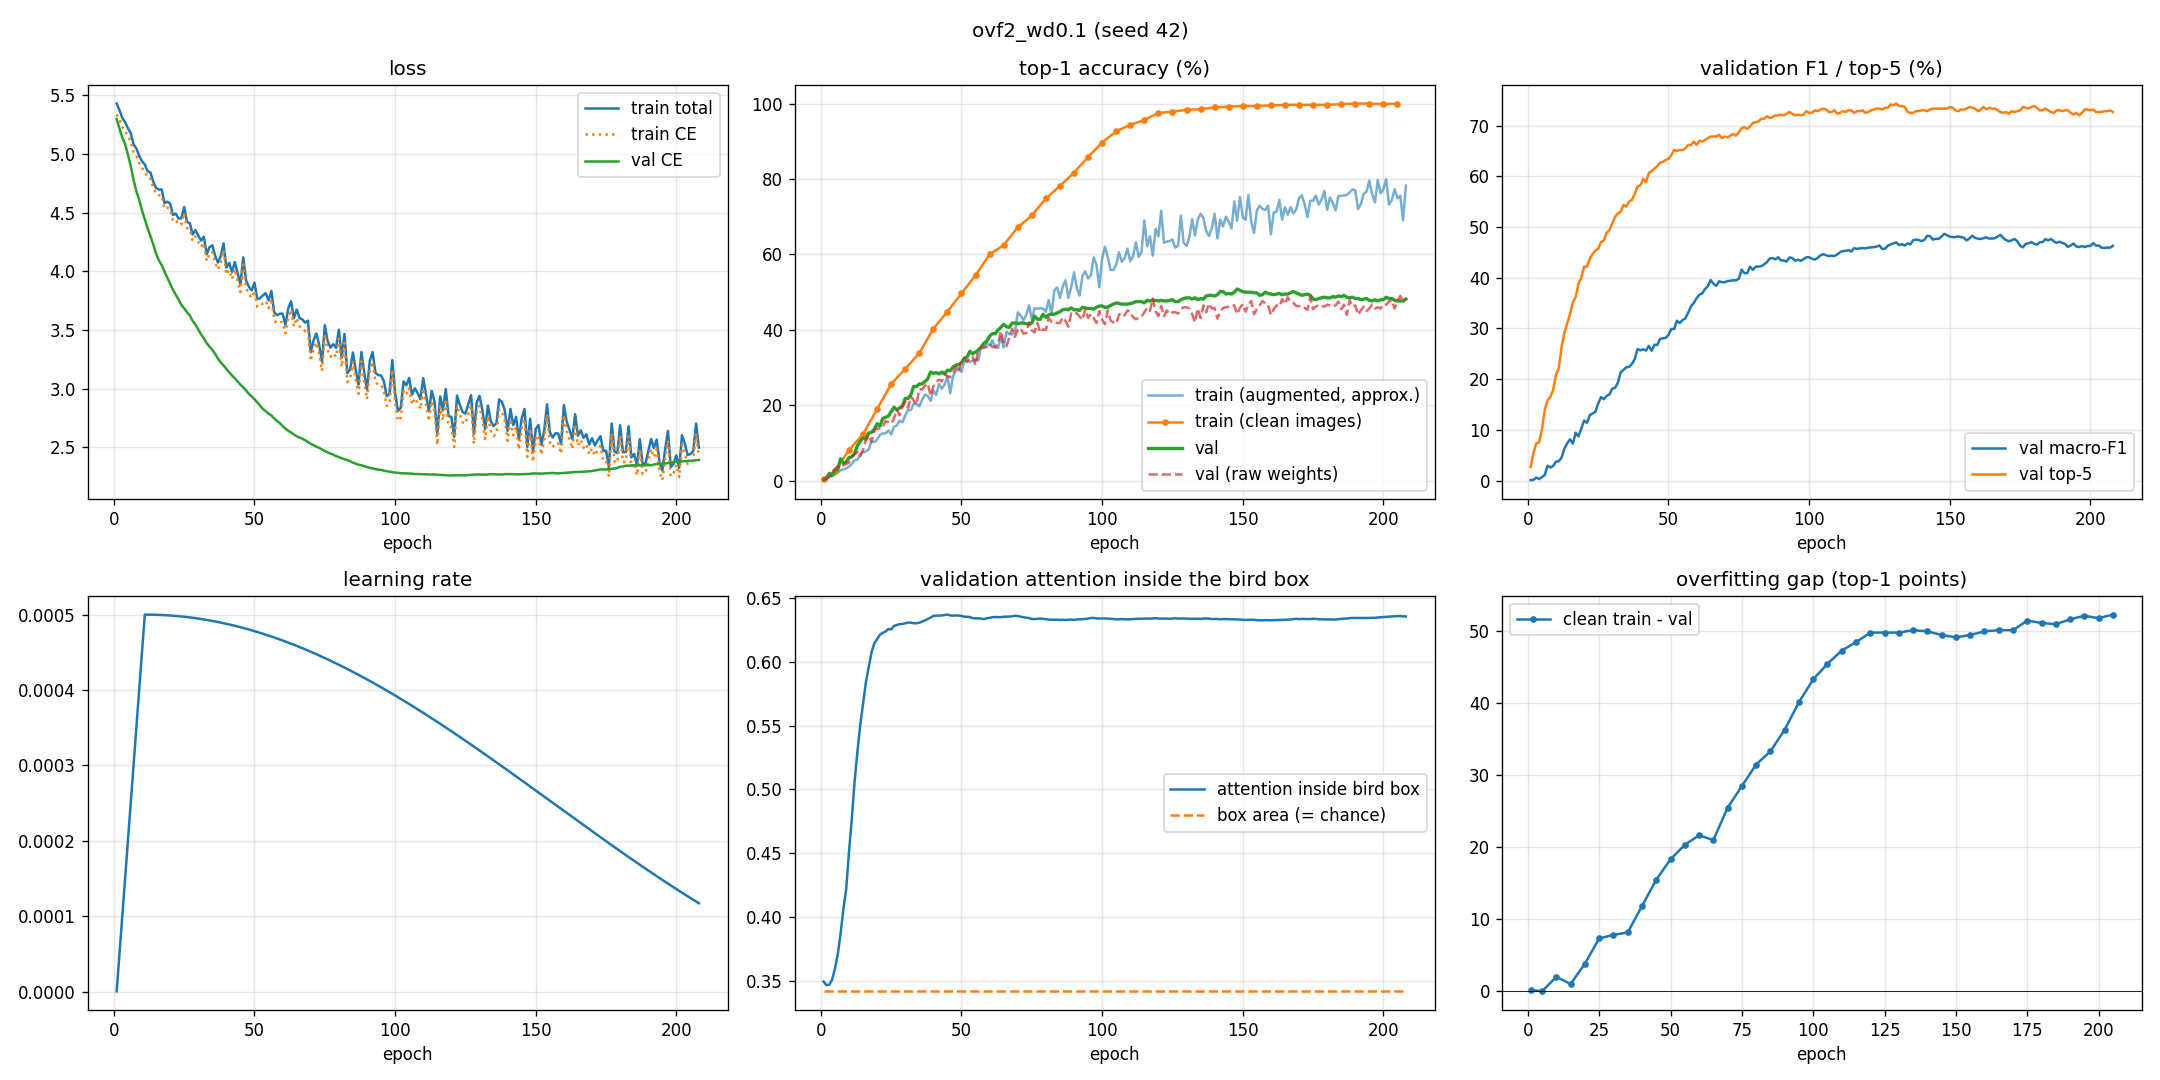

In [6]:
NAME = "ovf2_wd0.1"
exp = get_trial(NAME, SEED)
print("TRIAL", NAME, "|", overfit_trials()[NAME]["change"])
row = run_experiment(exp, PATHS, num_workers=NUM_WORKERS, step_print_every=STEP_PRINT_EVERY, resume=RESUME)
display(pd.Series({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()}))
run_dir = PATHS.results / NAME / f"seed{SEED}"
display(show_image(filename=str(run_dir / "curves.png")))

## 3.3 Trial 3: `ovf3_autoaug`

TRIAL ovf3_autoaug | augmentation tier 'strong' -> 'auto' (TrivialAugmentWide, bird box follows)


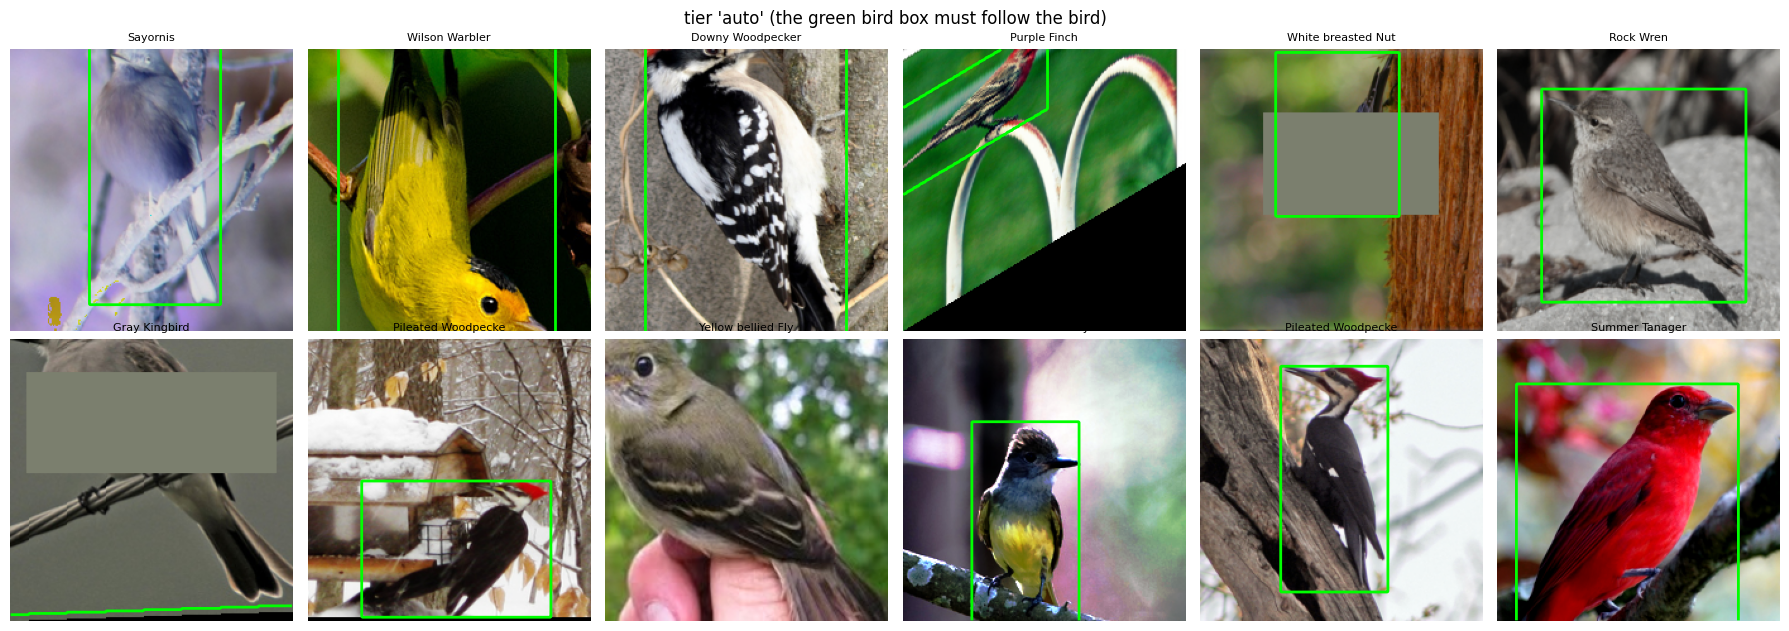

RUN ovf3_autoaug | seed 42 | device cuda | AMP True (torch.bfloat16)


model  4.27 M params | ModelConfig(img_size=224, num_classes=200, embed_dim=256, depth=8, heads=8, mlp_ratio=3.0, drop=0.0, attn_drop=0.0, drop_path=0.1, tok_groups=4, pool_after=None, pool_ratio=4, adj_mode='hadamard', use_sparse_gate=True, use_lfe=True, keep_abs_pos=False, use_multiscale=True, scales=(1, 2, 4, 0))


train  TrainConfig(epochs=300, batch_size=64, lr=0.0005, min_lr=1e-06, warmup_epochs=10, weight_decay=0.05, betas=(0.9, 0.999), grad_clip=1.0, label_smoothing=0.1, amp=True, aug_tier='auto', use_mixup_cutmix=True, use_bbox_loss=True, bbox_weight=0.1, use_ema=True, ema_decay=0.999, use_consistency=True, cons_logit_weight=1.0, cons_attn_weight=1.0, use_box_crop=True, box_crop_prob=0.3, box_crop_margin=(0.1, 0.4), best_metric='acc1', early_stop_patience=60, early_stop_start=30, clean_eval_every=5, clean_eval_size=600, snapshot_every=10, weights_every=50, plot_every=10)


data   splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | steps/epoch 84 | total steps 25,200



------------------------------------------------------------ EPOCH 001/300 ------------------------------------------------------------


...

worst 10 classes (F1):
 class_id           class_name  precision    recall        f1  support
       28        American Crow   9.523810  6.666667  7.843137       30
      101   Western Wood Pewee  15.000000 10.000000 12.000000       30
      116 Clay colored Sparrow  15.000000 10.344828 12.244898       29
       22     Brandt Cormorant  17.647059 10.344828 13.043478       29
      134         Bank Swallow  14.285714 13.333333 13.793103       30
       24    Pelagic Cormorant  16.666667 13.333333 14.814815       30
       29            Fish Crow  15.789474 20.000000 17.647059       30
       26        Shiny Cowbird  16.666667 20.000000 18.181818       30
       71      Pomarine Jaeger  20.833333 16.666667 18.518519       30
        2      Sooty Albatross  23.809524 17.857143 20.408163       28


best 10 classes (F1):
 class_id                class_name  precision    recall        f1  support
       54          Evening Grosbeak  96.296296 86.666667 91.228070       30
       15           Painted Bunting  88.888889 85.714286 87.272727       28
       82 White breasted Kingfisher  92.307692 80.000000 85.714286       30
       56    Rose breasted Grosbeak  88.888889 80.000000 84.210526       30
       11   Yellow headed Blackbird  77.419355 92.307692 84.210526       26
       69           Green Violetear  92.000000 76.666667 83.636364       30
      190     Red headed Woodpecker  88.461538 76.666667 82.142857       30
      191          Downy Woodpecker  82.758621 80.000000 81.355932       30
      163          Cerulean Warbler  82.142857 76.666667 79.310345       30
      188    Red bellied Woodpecker  77.419355 80.000000 78.688525       30


most frequent confusions (true -> predicted : count):
  Herring Gull -> California Gull : 9
  Pelagic Cormorant -> Red faced Cormorant : 8
  Horned Grebe -> Eared Grebe : 8
  Elegant Tern -> Caspian Tern : 8
  Artic Tern -> Common Tern : 7
  American Crow -> Fish Crow : 7
  Western Wood Pewee -> Olive sided Flycatcher : 7
  Anna Hummingbird -> Ruby throated Hummingbird : 7
  Black billed Cuckoo -> Yellow billed Cuckoo : 7
  Loggerhead Shrike -> Great Grey Shrike : 6
  American Crow -> Common Raven : 6
  Great Grey Shrike -> Loggerhead Shrike : 6
  Shiny Cowbird -> Fish Crow : 6
  Indigo Bunting -> Blue Grosbeak : 6
  Nelson Sharp tailed Sparrow -> Le Conte Sparrow : 6



Saved everything to C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\ovf3_autoaug\seed42


experiment                                                          ovf3_autoaug
seed                                                                          42
best_epoch                                                                   179
epochs_run                                                                   239
stopped_early                                                               True
train_time_s                                                            4720.245
sec_per_epoch                                                              19.75
best_val_acc1                                                             50.833
val_acc1_at_best                                                          50.833
overfit_gap_clean_minus_val                                                 48.5
test_acc1                                                                 50.259
test_acc5                                                                 75.785
test_macro_f1               

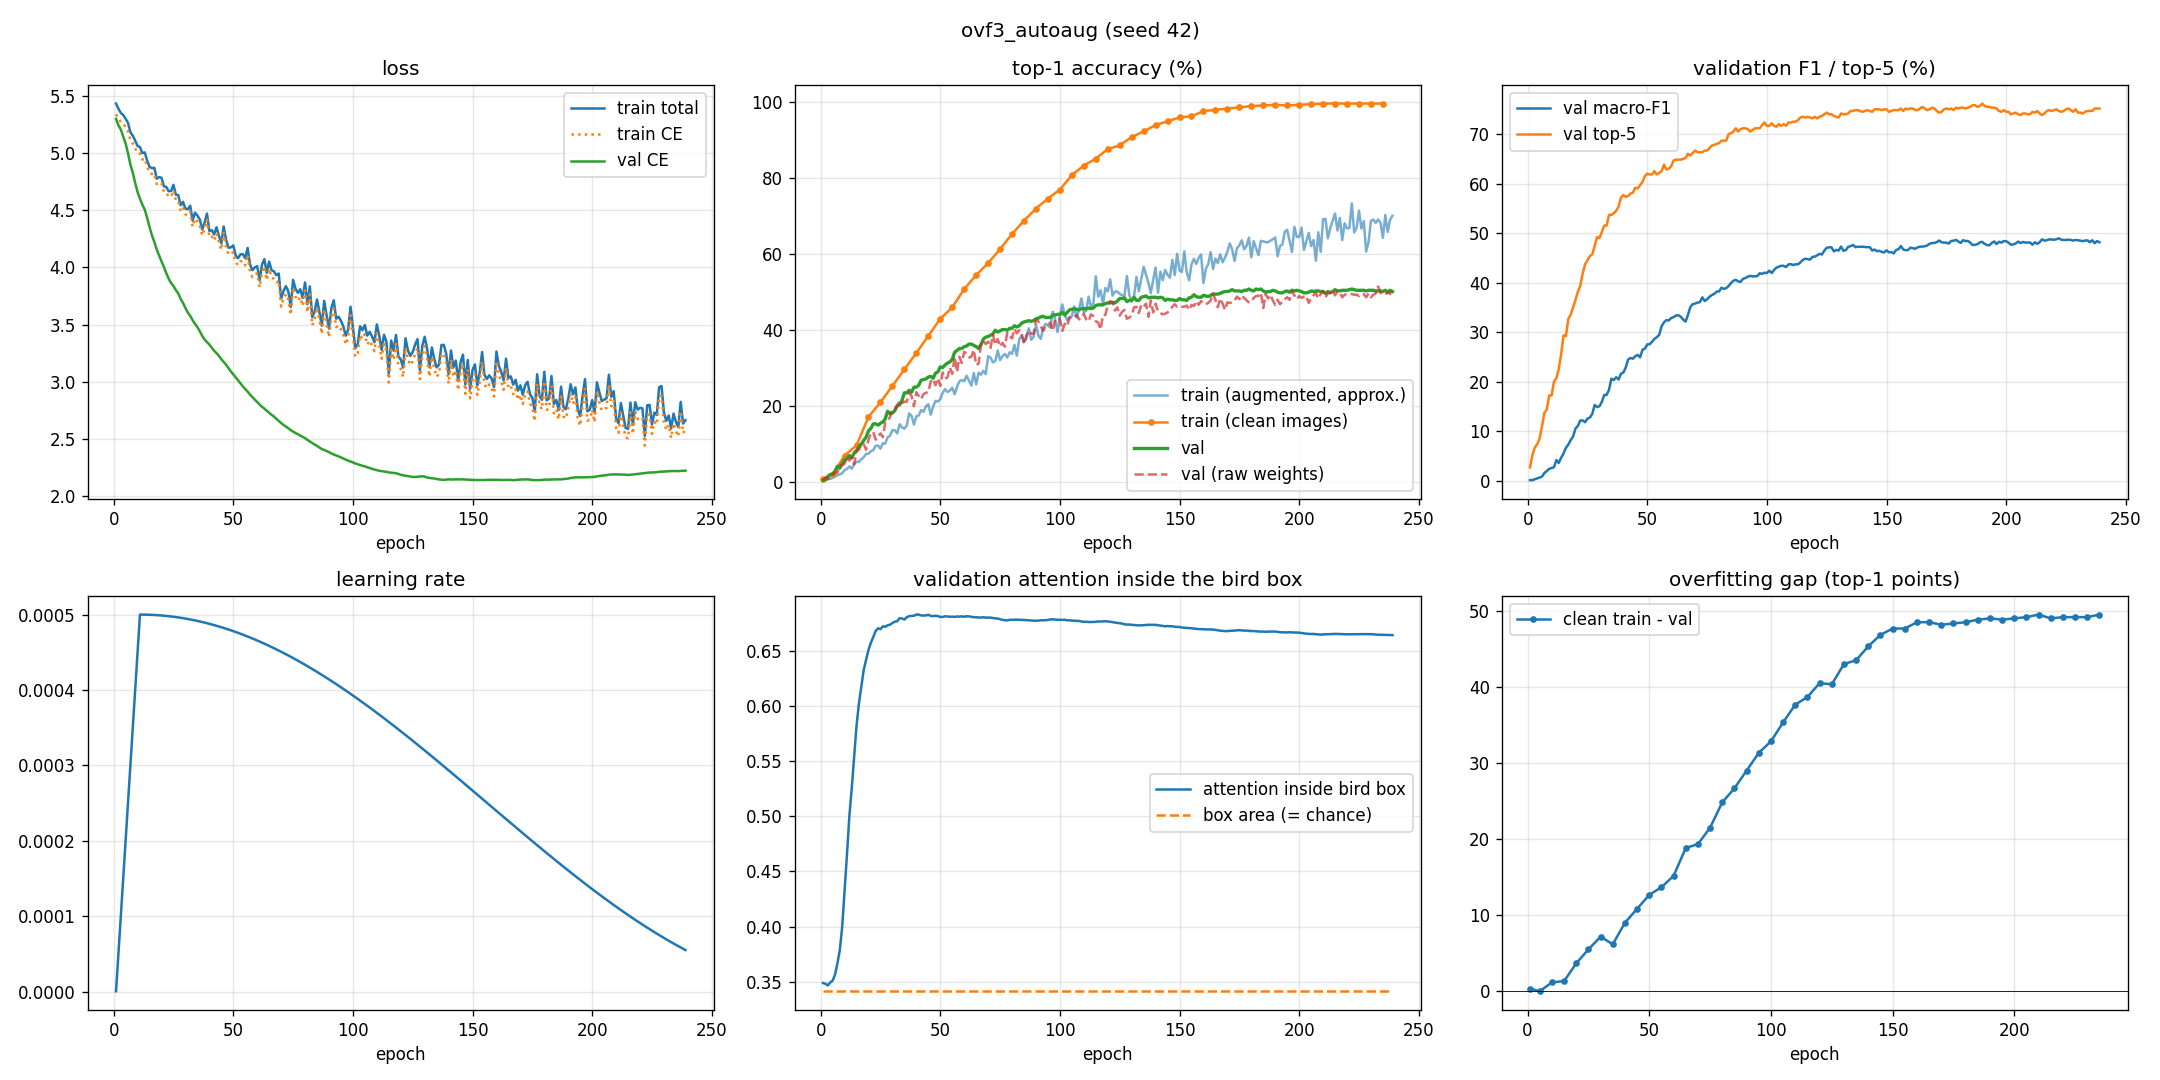

In [7]:
NAME = "ovf3_autoaug"
exp = get_trial(NAME, SEED)
print("TRIAL", NAME, "|", overfit_trials()[NAME]["change"])
info = load_data_info(PATHS)
ds_preview, _ = build_loaders(info, exp.train, SEED, num_workers=0, pin_memory=False)
(PATHS.results / "overfitting_trials").mkdir(parents=True, exist_ok=True)
viz.augmentation_preview(ds_preview["train"], info.mean, info.std, PATHS.results / "overfitting_trials" / "auto_aug_preview.png",
                         n=12, show=True, title="tier 'auto' (the green bird box must follow the bird)")
row = run_experiment(exp, PATHS, num_workers=NUM_WORKERS, step_print_every=STEP_PRINT_EVERY, resume=RESUME)
display(pd.Series({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()}))
run_dir = PATHS.results / NAME / f"seed{SEED}"
display(show_image(filename=str(run_dir / "curves.png")))

## 3.4 Trial 4: `ovf4_dropout0.1`

TRIAL ovf4_dropout0.1 | dropout 0 -> 0.1 in the MLP/projections and on the attention weights


RUN ovf4_dropout0.1 | seed 42 | device cuda | AMP True (torch.bfloat16)


model  4.27 M params | ModelConfig(img_size=224, num_classes=200, embed_dim=256, depth=8, heads=8, mlp_ratio=3.0, drop=0.1, attn_drop=0.1, drop_path=0.1, tok_groups=4, pool_after=None, pool_ratio=4, adj_mode='hadamard', use_sparse_gate=True, use_lfe=True, keep_abs_pos=False, use_multiscale=True, scales=(1, 2, 4, 0))


train  TrainConfig(epochs=300, batch_size=64, lr=0.0005, min_lr=1e-06, warmup_epochs=10, weight_decay=0.05, betas=(0.9, 0.999), grad_clip=1.0, label_smoothing=0.1, amp=True, aug_tier='strong', use_mixup_cutmix=True, use_bbox_loss=True, bbox_weight=0.1, use_ema=True, ema_decay=0.999, use_consistency=True, cons_logit_weight=1.0, cons_attn_weight=1.0, use_box_crop=True, box_crop_prob=0.3, box_crop_margin=(0.1, 0.4), best_metric='acc1', early_stop_patience=60, early_stop_start=30, clean_eval_every=5, clean_eval_size=600, snapshot_every=10, weights_every=50, plot_every=10)


data   splits {'train': 5394, 'val': 600, 'test': 5794} | classes 200 | steps/epoch 84 | total steps 25,200


...

worst 10 classes (F1):
 class_id           class_name  precision    recall        f1  support
      116 Clay colored Sparrow  12.500000 10.344828 11.320755       29
       29            Fish Crow  10.526316 13.333333 11.764706       30
      134         Bank Swallow  15.789474 10.000000 12.244898       30
       28        American Crow  15.789474 10.000000 12.244898       30
       90          Mockingbird  23.076923 10.000000 13.953488       30
       38     Least Flycatcher  16.666667 13.793103 15.094340       29
      141           Black Tern  17.391304 13.333333 15.094340       30
      195           House Wren  19.047619 13.333333 15.686275       30
      144         Elegant Tern  22.222222 13.333333 16.666667       30
      107   White necked Raven  19.230769 16.666667 17.857143       30


best 10 classes (F1):
 class_id             class_name  precision    recall        f1  support
       15        Painted Bunting  92.307692 85.714286 88.888889       28
       54       Evening Grosbeak  89.285714 83.333333 86.206897       30
      187    Pileated Woodpecker  91.666667 73.333333 81.481481       30
       69        Green Violetear  76.470588 86.666667 81.250000       30
       74              Green Jay  76.666667 85.185185 80.701754       27
      190  Red headed Woodpecker  82.142857 76.666667 79.310345       30
       47     European Goldfinch  82.142857 76.666667 79.310345       30
      188 Red bellied Woodpecker  72.222222 86.666667 78.787879       30
       56 Rose breasted Grosbeak  77.419355 80.000000 78.688525       30
       46     American Goldfinch  86.956522 66.666667 75.471698       30


most frequent confusions (true -> predicted : count):
  Horned Grebe -> Eared Grebe : 10
  American Crow -> Common Raven : 9
  Common Tern -> Artic Tern : 8
  Forsters Tern -> Least Tern : 7
  Loggerhead Shrike -> Great Grey Shrike : 7
  Elegant Tern -> Caspian Tern : 7
  American Crow -> Fish Crow : 6
  Elegant Tern -> Least Tern : 6
  Nelson Sharp tailed Sparrow -> Le Conte Sparrow : 6
  Long tailed Jaeger -> Pomarine Jaeger : 6
  Herring Gull -> California Gull : 6
  Cardinal -> Vermilion Flycatcher : 5
  Pine Grosbeak -> Purple Finch : 5
  Northern Fulmar -> Red legged Kittiwake : 5
  Black billed Cuckoo -> Mangrove Cuckoo : 5



Saved everything to C:\Users\sam\Downloads\Samruddhi\patchvision-vit-cub200\results\ovf4_dropout0.1\seed42


experiment                                                       ovf4_dropout0.1
seed                                                                          42
best_epoch                                                                   193
epochs_run                                                                   253
stopped_early                                                               True
train_time_s                                                            5171.184
sec_per_epoch                                                             20.439
best_val_acc1                                                               51.0
val_acc1_at_best                                                            51.0
overfit_gap_clean_minus_val                                               48.833
test_acc1                                                                 48.084
test_acc5                                                                 73.162
test_macro_f1               

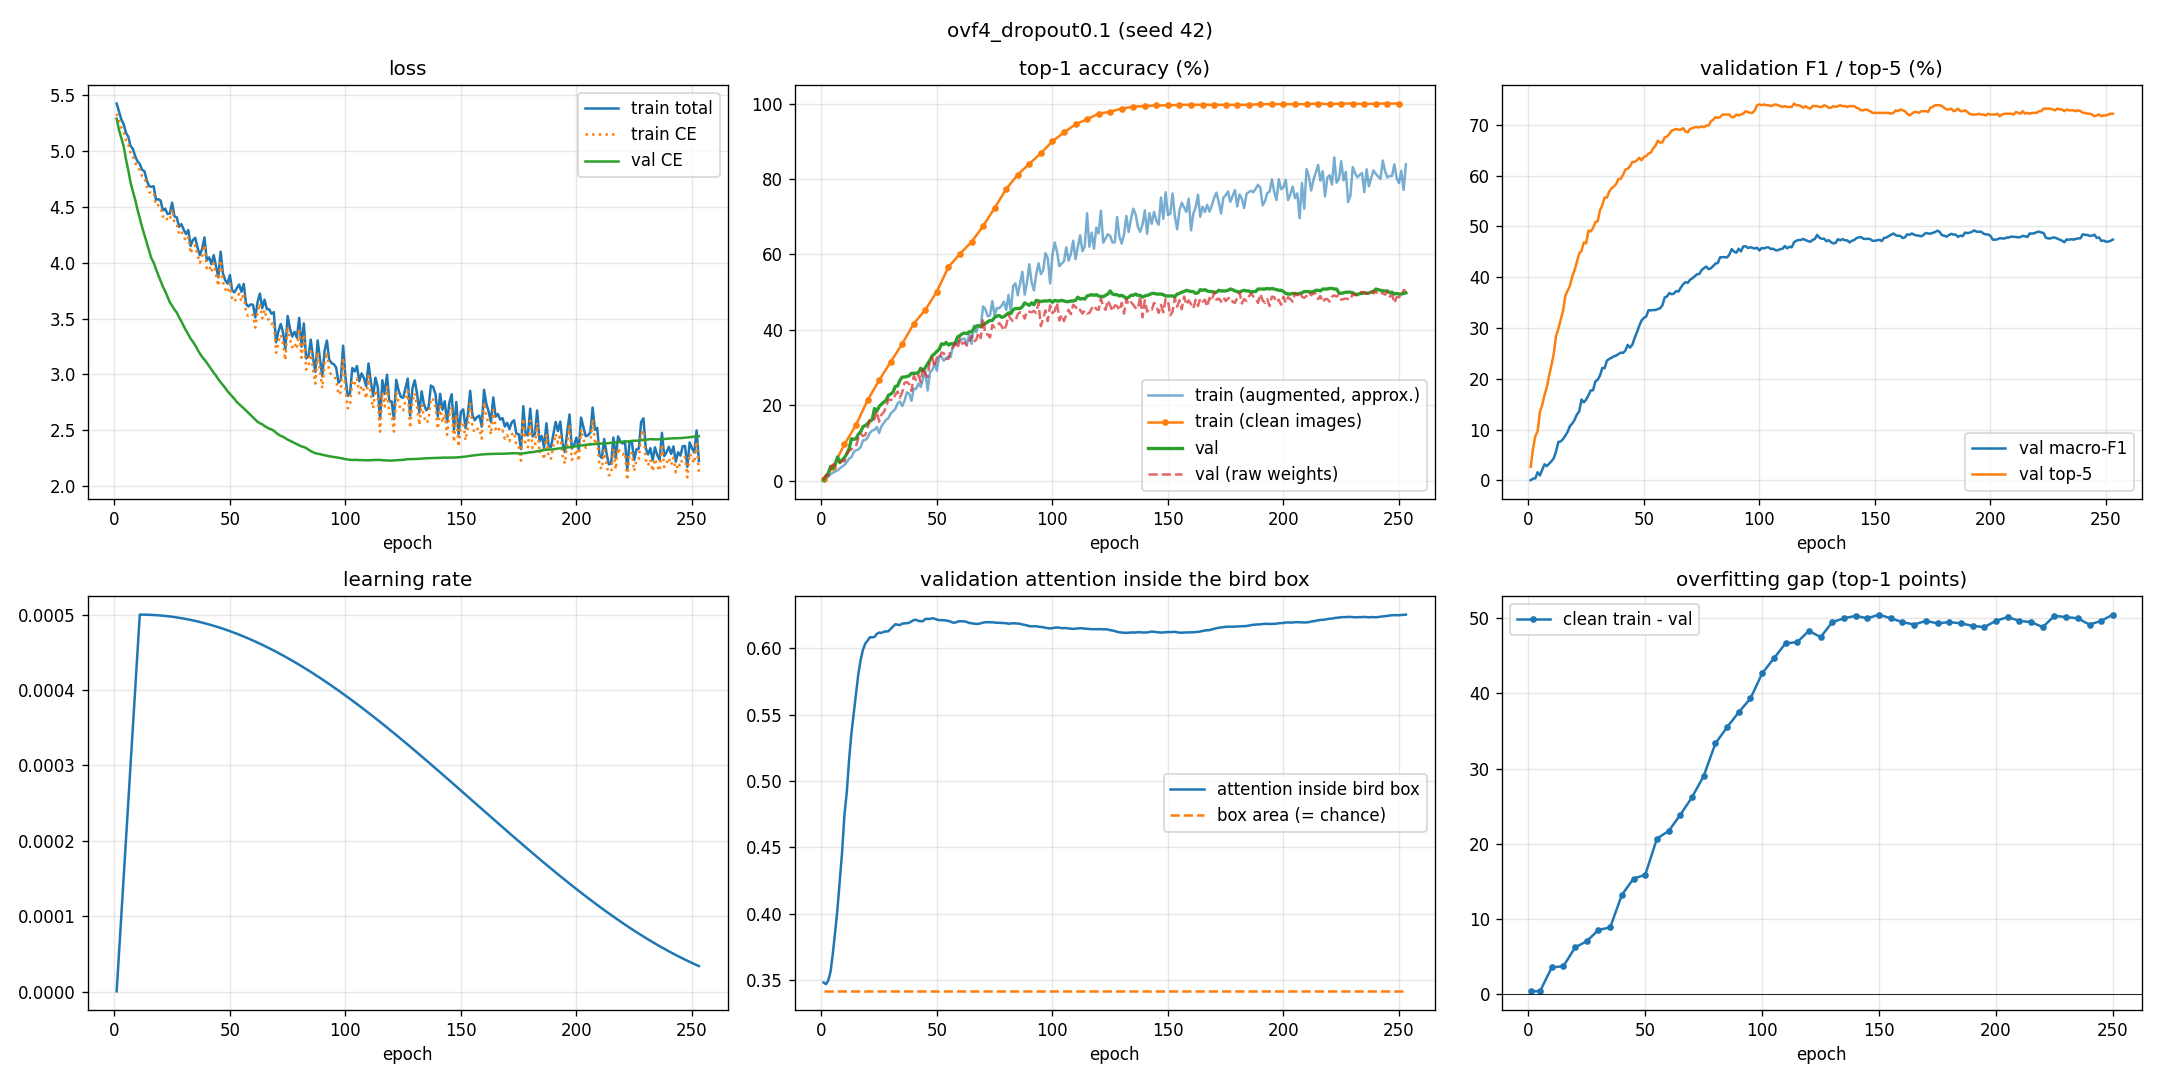

In [8]:
NAME = "ovf4_dropout0.1"
exp = get_trial(NAME, SEED)
print("TRIAL", NAME, "|", overfit_trials()[NAME]["change"])
row = run_experiment(exp, PATHS, num_workers=NUM_WORKERS, step_print_every=STEP_PRINT_EVERY, resume=RESUME)
display(pd.Series({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()}))
run_dir = PATHS.results / NAME / f"seed{SEED}"
display(show_image(filename=str(run_dir / "curves.png")))

## 4. Comparison (validation numbers decide; test numbers are only for the record)

,run,finished,epochs_run,best_val_acc1,smoothed_val_acc1,min_val_loss,min_val_loss_epoch,clean_train_acc_at_best,gap_at_best,val_attn_in_box,train_min
0,base,True,246,42.33,40.80,2.72,114,99.50,59.83,0.35,48.42
1,full,True,213,48.50,48.38,2.32,140,98.17,49.83,0.66,71.20
2,ovf1_droppath0.3,True,300,51.67,51.35,2.14,149,99.83,48.33,0.67,96.83
3,ovf2_wd0.1,True,208,50.83,50.07,2.26,120,99.33,49.17,0.64,69.09
4,ovf3_autoaug,True,239,50.83,50.57,2.14,167,99.00,48.50,0.66,78.67
5,ovf4_dropout0.1,True,253,51.00,50.82,2.23,120,99.83,48.83,0.63,86.19


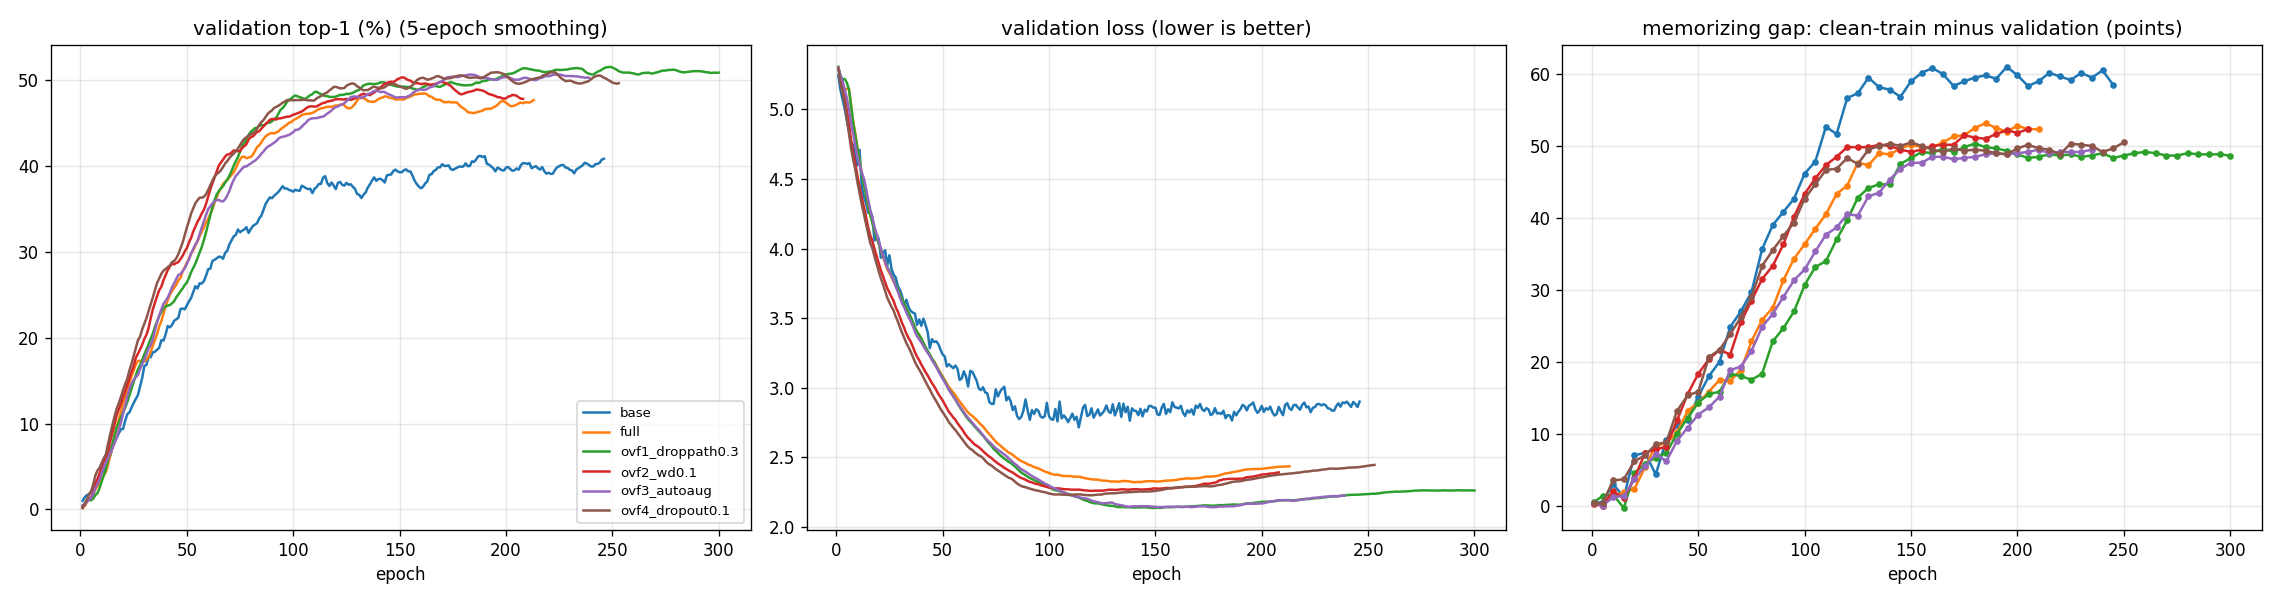

In [9]:
ALL = ["base", "full"] + TRIALS
table = compare_runs(PATHS, ALL, seed=SEED, out_name="overfitting_trials")
show_cols = ["run", "finished", "epochs_run", "best_val_acc1", "smoothed_val_acc1", "min_val_loss", "min_val_loss_epoch",
             "clean_train_acc_at_best", "gap_at_best", "val_attn_in_box", "train_min"]
display(table[show_cols].round(2))
display(show_image(filename=str(PATHS.results / "overfitting_trials" / "comparison.png")))

### Verdict, computed by the rule written at the top

In [10]:
f = table[table.run == "full"].iloc[0]
out = []
for _, r in table[table.run.isin(TRIALS)].iterrows():
    loss_gain = f.min_val_loss - r.min_val_loss
    acc_diff = r.smoothed_val_acc1 - f.smoothed_val_acc1
    win = (loss_gain >= 0.03) and (acc_diff >= -1.0)
    out.append({"trial": r.run, "min val loss: full - trial": round(loss_gain, 3),
                "smoothed val acc: trial - full (pts)": round(acc_diff, 2),
                "gap_at_best: trial - full (pts)": round(r.gap_at_best - f.gap_at_best, 1),
                "IMPROVEMENT (rule)": bool(win)})
verdict = pd.DataFrame(out)
display(verdict)
verdict.to_csv(PATHS.results / "overfitting_trials" / "verdict.csv", index=False)
print("winners to combine in the next run:", verdict.loc[verdict["IMPROVEMENT (rule)"], "trial"].tolist())

,trial,min val loss: full - trial,smoothed val acc: trial - full (pts),gap_at_best: trial - full (pts),IMPROVEMENT (rule)
0,ovf1_droppath0.3,0.186,2.97,-1.5,True
1,ovf2_wd0.1,0.063,1.68,-0.7,True
2,ovf3_autoaug,0.180,2.18,-1.3,True
3,ovf4_dropout0.1,0.095,2.43,-1.0,True


winners to combine in the next run: ['ovf1_droppath0.3', 'ovf2_wd0.1', 'ovf3_autoaug', 'ovf4_dropout0.1']
